# Steam game success: merging and cleaning the raw data

**Research question:** which characteristics of Steam games (genre, price, camera perspective, visual style,
narrative elements, gameplay features) are associated with higher player satisfaction and popularity?

This notebook takes the raw files our collectors produced and turns them into one analysis-ready table,
`data/processed/steam_games_clean.csv` (plus a `.json` copy).

| Source | Collected by | Raw file | How it was obtained |
|---|---|---|---|
| SteamSpy catalog | `src/collect_steamspy.py ids` | `data/raw/steamspy_page_{0,10,30}.json` | REST API (`request=all`) |
| SteamSpy tags *(optional)* | `src/collect_steamspy.py details` | `data/raw/steamspy_raw.json` | REST API (`request=appdetails`) |
| Steam Store | `src/collect_games_data.py` | `data/raw/games_data.csv` | REST API (`store.steampowered.com/api/appdetails`) |
| Steam Reviews | `collect_reviews.py` | `data/steam_reviews_summary.csv` | REST API (`IUserReviewsService/GetAppReviews`) |

None of the raw files are modified; everything below works on in-memory copies.

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/shilpatel/successOnSteam


## 1. Load the raw sources

In [2]:
ids = pd.read_csv(RAW / "game_ids.csv")

catalog_pages = []
for page in (0, 10, 30):
    with open(RAW / f"steamspy_page_{page}.json", encoding="utf-8") as f:
        page_data = json.load(f)           # dict keyed by appid (as a string)
    df = pd.DataFrame(page_data.values())
    df["catalog_page"] = page
    catalog_pages.append(df)
catalog_raw = pd.concat(catalog_pages, ignore_index=True)

store_raw = pd.read_csv(RAW / "games_data.csv")

# The reviews CSV exists twice in the repo (root and data/). Use data/ and confirm they agree.
reviews_raw = pd.read_csv(ROOT / "data" / "steam_reviews_summary.csv")
root_copy = ROOT / "steam_reviews_summary.csv"
if root_copy.exists():
    other = pd.read_csv(root_copy)
    same = other.drop(columns="collected_at").sort_values("appid").reset_index(drop=True).equals(
        reviews_raw.drop(columns="collected_at").sort_values("appid").reset_index(drop=True))
    print("Root copy of reviews CSV matches data/ copy:", same)

tags_path = RAW / "steamspy_raw.json"
HAVE_TAGS = tags_path.exists()

summary = pd.DataFrame({
    "rows": [len(ids), len(catalog_raw), len(store_raw), len(reviews_raw)],
    "columns": [ids.shape[1], catalog_raw.shape[1], store_raw.shape[1], reviews_raw.shape[1]],
}, index=["game_ids (our sample)", "SteamSpy catalog (3 pages)", "Store API", "Reviews API"])
display(summary)
print("SteamSpy tag file present:", HAVE_TAGS)

Root copy of reviews CSV matches data/ copy: True


,rows,columns
game_ids (our sample),200,3
SteamSpy catalog (3 pages),3000,18
Store API,200,9
Reviews API,200,8


SteamSpy tag file present: True


## 2. What's messy in the raw data

A quick look at the problems we have to fix before the sources can be joined and analysed.

In [3]:
sample_ids = ids["appid"].tolist()
cat_s = catalog_raw[catalog_raw["appid"].isin(sample_ids)]

print("SteamSpy: numbers stored as text")
display(cat_s[["appid", "name", "owners", "price", "initialprice", "discount", "score_rank", "userscore"]].head(5))
print("dtypes:", cat_s[["owners", "price", "initialprice", "discount", "score_rank"]].dtypes.astype(str).to_dict())

print("\nStore API: categories/genres packed into one string, dates as text")
display(store_raw[["appid", "name", "genres", "categories", "release_date"]].head(3))

print("\nStore API: games showing $0 that are NOT free-to-play (delisted or no price on the store)")
not_f2p = store_raw[(store_raw["final_price"] == 0) & ~store_raw["genres"].fillna("").str.contains("Free To Play")]
display(not_f2p[["appid", "name", "genres", "final_price"]])

print("\nStore API: untranslated category keys")
raw_keys = sorted({c for v in store_raw["categories"].dropna() for c in v.split("; ") if c.startswith("#")})
print(raw_keys)

print("\nReviews API: rating label replaced by a count for low-review games")
display(reviews_raw["review_score_desc"].value_counts().to_frame("games"))

print("\nMissing values per source:")
display(pd.DataFrame({
    "store": store_raw.isna().sum()[store_raw.isna().sum() > 0],
}).T if store_raw.isna().any().any() else "none")

SteamSpy: numbers stored as text


,appid,name,owners,price,initialprice,discount,score_rank,userscore
6,1063730,New World: Aeternum,"50,000,000 .. 100,000,000",5999,5999,0,,0
25,252490,Rust,"20,000,000 .. 50,000,000",3999,3999,0,,0
27,346110,ARK: Survival Evolved,"20,000,000 .. 50,000,000",1499,1499,0,,0
30,1491000,War Robots: Frontiers,"20,000,000 .. 50,000,000",0,0,0,,0
32,218620,PAYDAY 2,"20,000,000 .. 50,000,000",499,999,50,,0


dtypes: {'owners': 'str', 'price': 'str', 'initialprice': 'str', 'discount': 'str', 'score_rank': 'str'}

Store API: categories/genres packed into one string, dates as text


,appid,name,genres,categories,release_date
0,453480,Shadowverse CCG,Strategy; Free To Play,Single-player; Multi-player; PvP; Online PvP; ...,"Oct 27, 2016"
1,466240,Deceit,Action; Indie; Free To Play,Multi-player; PvP; Online PvP; Steam Achieveme...,"Mar 3, 2017"
2,252490,Rust,Action; Adventure; Indie; Massively Multiplaye...,Multi-player; MMO; PvP; Online PvP; Co-op; Onl...,"Feb 8, 2018"



Store API: games showing $0 that are NOT free-to-play (delisted or no price on the store)


,appid,name,genres,final_price
13,63380,Sniper Elite V2,Action,0.0
37,1063730,New World: Aeternum,Action; Adventure; Massively Multiplayer; RPG,0.0
45,17480,Command & Conquer™ Red Alert™ 3,Action; Strategy,0.0
50,1811260,EA SPORTS™ FIFA 23,Simulation; Sports,0.0
89,1894790,Stones Keeper: King Aurelius,Strategy,0.0
107,1042530,POWER,Massively Multiplayer; Simulation; Strategy,0.0
114,432260,Tiltagon,Action; Casual; Indie,0.0
137,1703080,F-15 Strike Eagle,Simulation,0.0
139,743550,COSMONAUT,Action; Adventure; Indie,0.0
142,699760,Triple Otakus Puzzle,Casual; Indie,0.0



Store API: untranslated category keys
['#category_contrast_controls', '#category_playable_at_your_own_pace']

Reviews API: rating label replaced by a count for low-review games


,games
review_score_desc,
Very Positive,81
Mixed,36
Mostly Positive,31
Positive,18
Overwhelmingly Positive,9
Mostly Negative,7
1 user reviews,7
3 user reviews,3
4 user reviews,2



Missing values per source:


,release_date
store,1


## 3. Clean the SteamSpy catalog

In [4]:
def parse_owners(s):
    """'50,000 .. 100,000' -> (50000, 100000)"""
    if not isinstance(s, str) or ".." not in s:
        return (np.nan, np.nan)
    lo, hi = (int(x.replace(",", "").strip()) for x in s.split(".."))
    return (lo, hi)

spy = cat_s.copy()
spy = spy.drop_duplicates("appid")
spy["name"] = spy["name"].str.strip()
spy[["owners_low", "owners_high"]] = spy["owners"].apply(lambda s: pd.Series(parse_owners(s)))
# geometric midpoint is a better central guess for ranges that span an order of magnitude
spy["owners_mid"] = np.sqrt(spy["owners_low"].clip(lower=1) * spy["owners_high"])
for col in ("price", "initialprice"):
    spy[col] = pd.to_numeric(spy[col], errors="coerce") / 100          # cents -> dollars
spy["discount"] = pd.to_numeric(spy["discount"], errors="coerce")

# score_rank is blank and userscore is 0 for every game: SteamSpy no longer fills them
print("score_rank values:", spy["score_rank"].unique(), "| userscore values:", spy["userscore"].unique())
# playtime fields are 0 for every row in the 'all' listing, so they carry no information either
print("non-zero playtime rows:", (spy[["average_forever", "median_forever"]] != 0).any(axis=1).sum())

spy = spy.rename(columns={
    "price": "spy_price", "initialprice": "spy_initial_price", "discount": "spy_discount",
    "positive": "spy_positive", "negative": "spy_negative", "ccu": "peak_ccu_yesterday",
    "owners": "owners_range",
})[["appid", "name", "developer", "publisher", "catalog_page", "owners_range", "owners_low",
    "owners_high", "owners_mid", "spy_price", "spy_initial_price", "spy_discount",
    "spy_positive", "spy_negative", "peak_ccu_yesterday"]]

display(spy[["name", "owners_range", "owners_low", "owners_high", "owners_mid", "spy_price"]].head())

score_rank values: <StringArray>
['']
Length: 1, dtype: str | userscore values: [0]
non-zero playtime rows: 0


,name,owners_range,owners_low,owners_high,owners_mid,spy_price
6,New World: Aeternum,"50,000,000 .. 100,000,000",50000000,100000000,7.071068e+07,59.99
25,Rust,"20,000,000 .. 50,000,000",20000000,50000000,3.162278e+07,39.99
27,ARK: Survival Evolved,"20,000,000 .. 50,000,000",20000000,50000000,3.162278e+07,14.99
30,War Robots: Frontiers,"20,000,000 .. 50,000,000",20000000,50000000,3.162278e+07,0.00
32,PAYDAY 2,"20,000,000 .. 50,000,000",20000000,50000000,3.162278e+07,4.99


## 4. Clean the Steam Store data

In [5]:
store = store_raw.copy()

# --- release date: text -> datetime -------------------------------------------------------
store["release_date_raw"] = store["release_date"]
store["release_date"] = pd.to_datetime(store["release_date"], format="%b %d, %Y", errors="coerce")
bad = store["release_date"].isna() & store["release_date_raw"].notna()
if bad.any():   # fall back to a looser parser for other formats ("Feb 2019", "Q3 2025", ...)
    store.loc[bad, "release_date"] = pd.to_datetime(store.loc[bad, "release_date_raw"], errors="coerce")
store["release_year"] = store["release_date"].dt.year.astype("Int64")
store["release_month"] = store["release_date"].dt.month.astype("Int64")
print("Unparsed / missing release dates:")
display(store.loc[store["release_date"].isna(), ["appid", "name", "release_date_raw"]])

# --- price: separate 'free' from 'no price listed' --------------------------------------
store["is_free_to_play"] = store["genres"].fillna("").str.contains("Free To Play")
store["price_missing"] = (store["final_price"] == 0) & ~store["is_free_to_play"]
store.loc[store["price_missing"], ["initial_price", "final_price"]] = np.nan
store["on_sale"] = store["final_price"] < store["initial_price"]

# --- genres / categories: one string -> yes/no columns ----------------------------------
def split_list(s):
    return [x.strip() for x in s.split(";")] if isinstance(s, str) else []

CATEGORY_FIXES = {   # Steam sometimes returns localisation keys instead of labels
    "#category_contrast_controls": "Contrast Controls",
    "#category_playable_at_your_own_pace": "Playable at Your Own Pace",
    "VR Supported": "VR Support",
}
store["genre_list"] = store["genres"].apply(split_list)
store["category_list"] = store["categories"].apply(
    lambda s: sorted({CATEGORY_FIXES.get(c, c) for c in split_list(s)}))

def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

genre_dummies = (store["genre_list"].explode().str.get_dummies()
                 .groupby(level=0).max().add_prefix("genre_"))
genre_dummies.columns = ["genre_" + slug(c[6:]) for c in genre_dummies.columns]

cats = store["category_list"]
has = lambda *names: cats.apply(lambda lst: any(n in lst for n in names))
feature_flags = pd.DataFrame({
    "single_player": has("Single-player"),
    "multiplayer": has("Multi-player", "MMO", "Online PvP", "PvP", "Co-op", "Online Co-op",
                       "LAN Co-op", "LAN PvP", "Shared/Split Screen", "Cross-Platform Multiplayer"),
    "online_pvp": has("Online PvP", "PvP"),
    "co_op": has("Co-op", "Online Co-op", "LAN Co-op", "Shared/Split Screen Co-op"),
    "mmo": has("MMO"),
    "steam_achievements": has("Steam Achievements"),
    "steam_workshop": has("Steam Workshop"),
    "controller_full": has("Full controller support"),
    "controller_partial": has("Partial Controller Support"),
    "in_app_purchases": has("In-App Purchases"),
    "vr": has("VR Support", "VR Only"),
})
feature_flags["n_categories"] = cats.str.len()
feature_flags["n_genres"] = store["genre_list"].str.len()

store = pd.concat([store, genre_dummies, feature_flags], axis=1)
store["genres"] = store["genre_list"].str.join("; ")
store["categories"] = store["category_list"].str.join("; ")
store = store.drop(columns=["genre_list", "category_list", "release_date_raw", "type"])
store = store.rename(columns={"name": "store_name", "description": "short_description"})

display(store[["store_name", "release_date", "final_price", "is_free_to_play", "price_missing",
               "single_player", "multiplayer", "co_op"]].head())
print("Genre columns:", list(genre_dummies.columns))

Unparsed / missing release dates:


,appid,name,release_date_raw
13,63380,Sniper Elite V2,NaN


,store_name,release_date,final_price,is_free_to_play,price_missing,single_player,multiplayer,co_op
0,Shadowverse CCG,2016-10-27,0.00,True,False,True,True,False
1,Deceit,2017-03-03,0.00,True,False,False,True,False
2,Rust,2018-02-08,39.99,False,False,False,True,True
3,Wolcen: Lords of Mayhem,2020-02-13,19.99,False,False,True,False,False
4,Middle-earth™: Shadow of War™,2017-10-09,49.99,False,False,True,False,False


Genre columns: ['genre_action', 'genre_adventure', 'genre_audio_production', 'genre_casual', 'genre_early_access', 'genre_free_to_play', 'genre_indie', 'genre_massively_multiplayer', 'genre_rpg', 'genre_racing', 'genre_simulation', 'genre_sports', 'genre_strategy', 'genre_utilities']


## 5. Clean the review summaries

In [6]:
reviews = reviews_raw.drop_duplicates("appid").copy()

# Steam only gives a text rating once a game has ~10 reviews; below that it returns "N user reviews"
count_label = reviews["review_score_desc"].str.fullmatch(r"\d+ user reviews?")
reviews["rating_label"] = reviews["review_score_desc"].where(~count_label)
reviews["low_review_count"] = count_label | (reviews["total_reviews"] < 10)

RATING_ORDER = ["Overwhelmingly Negative", "Very Negative", "Negative", "Mostly Negative", "Mixed",
                "Mostly Positive", "Positive", "Very Positive", "Overwhelmingly Positive"]
reviews["rating_label"] = pd.Categorical(reviews["rating_label"], categories=RATING_ORDER, ordered=True)

# Percent positive is noisy for tiny samples (1 of 1 = 100%). The Wilson lower bound
# shrinks small samples toward 0, so it ranks a 95% game with 10,000 reviews above a 100% game with 3.
def wilson_lower(pos, n, z=1.96):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    denom = 1 + z**2 / n
    centre = p + z**2 / (2 * n)
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return np.where(n > 0, (centre - margin) / denom, np.nan)

pos, neg = reviews["total_positive"], reviews["total_negative"]
reviews["review_score_wilson"] = wilson_lower(pos, pos + neg).round(4)
reviews["log_total_reviews"] = np.log10(reviews["total_reviews"].clip(lower=1)).round(3)
reviews["collected_at"] = pd.to_datetime(reviews["collected_at"], utc=True)
reviews = reviews.drop(columns=["review_score_desc"]).rename(columns={"review_score": "review_score_code",
                                                                       "collected_at": "reviews_collected_at"})

display(reviews.sort_values("total_reviews").head(6)[
    ["appid", "total_reviews", "positive_percentage", "rating_label", "low_review_count", "review_score_wilson"]])

,appid,total_reviews,positive_percentage,rating_label,low_review_count,review_score_wilson
137,1703080,1,100.0,NaN,True,0.2065
95,1740180,1,100.0,NaN,True,0.2065
149,2229150,1,0.0,NaN,True,0.0000
143,1060840,1,100.0,NaN,True,0.2065
141,701880,1,100.0,NaN,True,0.2065
170,1673800,1,100.0,NaN,True,0.2065


## 6. SteamSpy user tags → perspective, art style, narrative

The Store API has no perspective or art-style fields, so these come from SteamSpy's community tags
(`collect_steamspy.py details`). Each tag has a vote count; we keep each design tag's **share of the
game's tag votes** and derive one label per dimension (the most-voted tag in that group).

If `data/raw/steamspy_raw.json` has not been collected yet, these columns are created empty and the
notebook still runs. Re-run it after collecting the tags to fill them in.

In [7]:
TAG_GROUPS = {
    "perspective": ["First-Person", "Third Person", "Top-Down", "Isometric", "Side Scroller", "2.5D"],
    "art_style":   ["Pixel Graphics", "Realistic", "Anime", "Cartoony", "Cartoon", "Stylized",
                    "Hand-drawn", "Minimalist", "Retro", "Colorful", "Cute", "Abstract"],
    "narrative":   ["Story Rich", "Choices Matter", "Multiple Endings", "Narration",
                    "Interactive Fiction", "Visual Novel", "Lore-Rich"],
    "dimension":   ["2D", "3D"],
}
ALL_DESIGN_TAGS = [t for group in TAG_GROUPS.values() for t in group]

def tag_features(tags):
    """tags: dict {tag: votes} (SteamSpy returns [] when a game has none)."""
    tags = tags if isinstance(tags, dict) else {}
    total = sum(tags.values()) or np.nan
    row = {"n_tags": len(tags), "top_tags": "; ".join(sorted(tags, key=tags.get, reverse=True)[:10])}
    for t in ALL_DESIGN_TAGS:
        row["tag_" + slug(t)] = round(tags.get(t, 0) / total, 4) if total == total else np.nan
    for group, members in TAG_GROUPS.items():
        present = {t: tags[t] for t in members if t in tags}
        row[group] = max(present, key=present.get) if present else np.nan
    row["story_rich"] = "Story Rich" in tags if tags else np.nan
    return row

if HAVE_TAGS:
    with open(tags_path, encoding="utf-8") as f:
        records = json.load(f)["records"]
    tag_df = pd.DataFrame([{"appid": int(a), **tag_features(r.get("tags"))} for a, r in records.items()])
    print(f"Tags loaded for {len(tag_df)} of {len(ids)} games")
    for g in TAG_GROUPS:
        display(tag_df[g].value_counts(dropna=False).to_frame(g))
else:
    empty = tag_features({})
    tag_df = pd.DataFrame([{"appid": a, **{k: np.nan for k in empty}} for a in ids["appid"]])
    display(Markdown("> **Tags not collected yet.** Run `python src/collect_steamspy.py` and type "
                     "`details`, then re-run this notebook. Tag columns are empty for now."))

Tags loaded for 200 of 200 games


,perspective
perspective,
NaN,103
First-Person,50
Third Person,24
Isometric,11
Top-Down,8
Side Scroller,3
2.5D,1


,art_style
art_style,
NaN,93
Realistic,23
Pixel Graphics,20
Anime,19
Cute,8
Retro,8
Minimalist,7
Colorful,7
Stylized,5


,narrative
narrative,
NaN,137
Story Rich,34
Visual Novel,11
Choices Matter,5
Multiple Endings,5
Interactive Fiction,5
Narration,2
Lore-Rich,1


,dimension
dimension,
NaN,121
2D,44
3D,35


## 7. Merge everything on `appid`

In [8]:
base = ids.rename(columns={"source_page": "sample_page"})[["appid", "sample_page"]]

merged = (base
          .merge(spy, on="appid", how="left", validate="one_to_one", indicator="_spy")
          .merge(store, on="appid", how="left", validate="one_to_one", indicator="_store")
          .merge(reviews, on="appid", how="left", validate="one_to_one", indicator="_reviews")
          .merge(tag_df, on="appid", how="left", validate="one_to_one"))

coverage = pd.DataFrame({src: (merged[f"_{src}"] == "both").sum()
                         for src in ("spy", "store", "reviews")}, index=["games matched"])
coverage["tags"] = merged["n_tags"].notna().sum()
display(coverage)
merged = merged.drop(columns=["_spy", "_store", "_reviews"])

# Name check across sources (SteamSpy vs Store)
norm = lambda s: s.str.replace(r"[™®©]", "", regex=True).str.casefold().str.strip()
name_diff = merged[merged["name"] != merged["store_name"]]
real_diff = merged[norm(merged["name"]) != norm(merged["store_name"])]
print(f"Name differs between SteamSpy and Store for {len(name_diff)} games; "
      f"{len(name_diff) - len(real_diff)} of them only by ™/®/© symbols. We keep SteamSpy's cleaner name.")
display(name_diff[["appid", "name", "store_name"]].head(10))
if len(real_diff):
    print("Genuine name differences:")
    display(real_diff[["appid", "name", "store_name"]])
merged = merged.drop(columns="store_name")

# Price check: Store is the source of truth, SteamSpy fills prices missing from the store
filled = merged["final_price"].isna() & merged["spy_price"].gt(0)
merged["price_source"] = np.where(merged["final_price"].notna(), "store",
                                  np.where(filled, "steamspy", "missing"))
merged.loc[filled, "initial_price"] = merged.loc[filled, "spy_initial_price"]
merged.loc[filled, "final_price"] = merged.loc[filled, "spy_price"]
display(merged["price_source"].value_counts().to_frame("games"))

,spy,store,reviews,tags
games matched,200,200,200,200


Name differs between SteamSpy and Store for 8 games; 7 of them only by ™/®/© symbols. We keep SteamSpy's cleaner name.


,appid,name,store_name
4,356190,Middle-earth: Shadow of War,Middle-earth™: Shadow of War™
6,1238840,Battlefield 1,Battlefield™ 1
14,289070,Sid Meier’s Civilization VI,Sid Meier’s Civilization® VI
26,518790,theHunter: Call of the Wild,theHunter: Call of the Wild™
36,3910,Sid Meier's Civilization III Complete,Sid Meier's Civilization® III Complete
45,17480,Command & Conquer: Red Alert 3,Command & Conquer™ Red Alert™ 3
46,15100,Assassin's Creed: Director's Cut Edition,Assassin's Creed™: Director's Cut Edition
50,1811260,EA SPORTS FIFA 23,EA SPORTS™ FIFA 23


Genuine name differences:


,appid,name,store_name
45,17480,Command & Conquer: Red Alert 3,Command & Conquer™ Red Alert™ 3


,games
price_source,
store,188
missing,8
steamspy,4


## 8. Final column order and save

In [9]:
id_cols      = ["appid", "name", "developer", "publisher", "release_date", "release_year", "release_month",
                "short_description", "sample_page", "catalog_page"]
price_cols   = ["initial_price", "final_price", "on_sale", "is_free_to_play", "price_missing", "price_source"]
success_cols = ["total_reviews", "total_positive", "total_negative", "positive_percentage",
                "review_score_wilson", "log_total_reviews", "rating_label", "review_score_code",
                "low_review_count", "owners_range", "owners_low", "owners_high", "owners_mid",
                "peak_ccu_yesterday"]
design_cols  = (["genres", "n_genres"] + [c for c in merged if c.startswith("genre_")]
                + ["categories", "n_categories", "single_player", "multiplayer", "online_pvp", "co_op", "mmo",
                   "steam_achievements", "steam_workshop", "controller_full", "controller_partial",
                   "in_app_purchases", "vr"]
                + ["perspective", "art_style", "narrative", "dimension", "story_rich", "n_tags", "top_tags"]
                + [c for c in merged if c.startswith("tag_")])
meta_cols    = ["reviews_collected_at"]
order = id_cols + price_cols + success_cols + design_cols + meta_cols
assert set(order) >= set(merged.columns) - {"spy_price", "spy_initial_price", "spy_discount",
                                            "spy_positive", "spy_negative"}, "unplaced columns"
final = merged[order].sort_values("appid").reset_index(drop=True)

assert final["appid"].is_unique
assert len(final) == len(ids)

final.to_csv(OUT / "steam_games_clean.csv", index=False)
final.to_json(OUT / "steam_games_clean.json", orient="records", indent=2, date_format="iso")
print(f"Saved {final.shape[0]} games x {final.shape[1]} columns to {OUT}")
display(final.head())

Saved 200 games x 94 columns to /Users/shilpatel/successOnSteam/data/processed


,appid,name,developer,publisher,release_date,release_year,release_month,short_description,sample_page,catalog_page,initial_price,final_price,on_sale,is_free_to_play,price_missing,price_source,total_reviews,total_positive,total_negative,positive_percentage,review_score_wilson,log_total_reviews,rating_label,review_score_code,low_review_count,...,tag_isometric,tag_side_scroller,tag_2_5d,tag_pixel_graphics,tag_realistic,tag_anime,tag_cartoony,tag_cartoon,tag_stylized,tag_hand_drawn,tag_minimalist,tag_retro,tag_colorful,tag_cute,tag_abstract,tag_story_rich,tag_choices_matter,tag_multiple_endings,tag_narration,tag_interactive_fiction,tag_visual_novel,tag_lore_rich,tag_2d,tag_3d,reviews_collected_at
0,3800,Advent Rising,"GlyphX Games, Cavetap",Ziggurat,2006-09-14,2006,9,A common legend pervades the galaxy-that of a ...,10,10,9.99,2.49,True,False,False,store,592,457,135,77.20,0.7365,2.772,Mostly Positive,6,False,...,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1048,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,2026-10-25 22:53:52.071187+00:00
1,3910,Sid Meier's Civilization III Complete,Firaxis Games,2K,2006-10-25,2006,10,"Sid Meier's Civilization III: Complete, the la...",0,0,4.99,4.99,False,False,False,store,7842,7014,828,89.44,0.8874,3.894,Very Positive,8,False,...,0.0072,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,2026-10-25 22:52:49.413470+00:00
2,8500,EVE Online,CCP,CCP,2010-12-15,2010,12,Over 20 years of legendary space battles! Expl...,0,0,0.00,0.00,False,True,False,store,39713,29123,10590,73.33,0.7290,4.599,Mostly Positive,6,False,...,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0,0.0341,0.0,0.0000,2026-10-25 22:52:45.846828+00:00
3,8980,Borderlands Game of the Year,Gearbox Software,2K,2023-08-31,2023,8,Get ready for the mind blowing insanity! Play ...,0,0,29.99,29.99,False,False,False,store,31945,28668,3277,89.74,0.8940,4.504,Very Positive,8,False,...,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,2026-10-25 22:52:11.874572+00:00
4,15100,Assassin's Creed: Director's Cut Edition,Ubisoft Montreal,Ubisoft,2008-04-09,2008,4,Assassin's Creed™ is the next-gen game develop...,0,0,19.99,19.99,False,False,False,store,25614,20624,4990,80.52,0.8003,4.408,Very Positive,8,False,...,0.0000,0.0,0.0,0.0,0.0473,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0481,0.0,0.0,0.0455,0.0,0.0,0.0000,0.0,0.0467,2026-10-25 22:53:07.015486+00:00


## 9. Data quality report

In [10]:
tag_cols = [c for c in final if c.startswith("tag_")] + ["perspective", "art_style", "narrative",
                                                         "dimension", "story_rich", "n_tags", "top_tags"]
check = final if HAVE_TAGS else final.drop(columns=tag_cols)
if not HAVE_TAGS:
    print(f"(Skipping {len(tag_cols)} tag columns: empty until SteamSpy tags are collected.)")
missing = check.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display((missing.to_frame("missing").assign(pct=lambda d: (d["missing"] / len(final) * 100).round(1))
         if len(missing) else "No missing values"))
display(final.describe(include=[np.number]).T[["count", "mean", "50%", "min", "max"]].round(2).head(20))

,missing,pct
narrative,137,68.5
dimension,121,60.5
perspective,103,51.5
art_style,93,46.5
rating_label,15,7.5
initial_price,8,4.0
final_price,8,4.0
release_date,1,0.5
release_year,1,0.5
release_month,1,0.5


,count,mean,50%,min,max
appid,200.0,1101494.165,774521.0,3800.0,3397690.0
release_year,199.0,2018.889447,2019.0,2006.0,2026.0
release_month,199.0,6.678392,7.0,1.0,12.0
sample_page,200.0,13.25,10.0,0.0,30.0
catalog_page,200.0,13.25,10.0,0.0,30.0
initial_price,192.0,13.260938,9.99,0.0,59.99
final_price,192.0,12.477083,9.99,0.0,59.99
total_reviews,200.0,46232.85,564.0,1.0,1409424.0
total_positive,200.0,39644.995,451.5,0.0,1221414.0
total_negative,200.0,6587.855,98.0,0.0,188010.0


## 10. First look

Quick charts to sanity-check the cleaned data. These are descriptive only; the sample is 200 games across
three popularity tiers of the SteamSpy catalog, not a random sample of Steam.

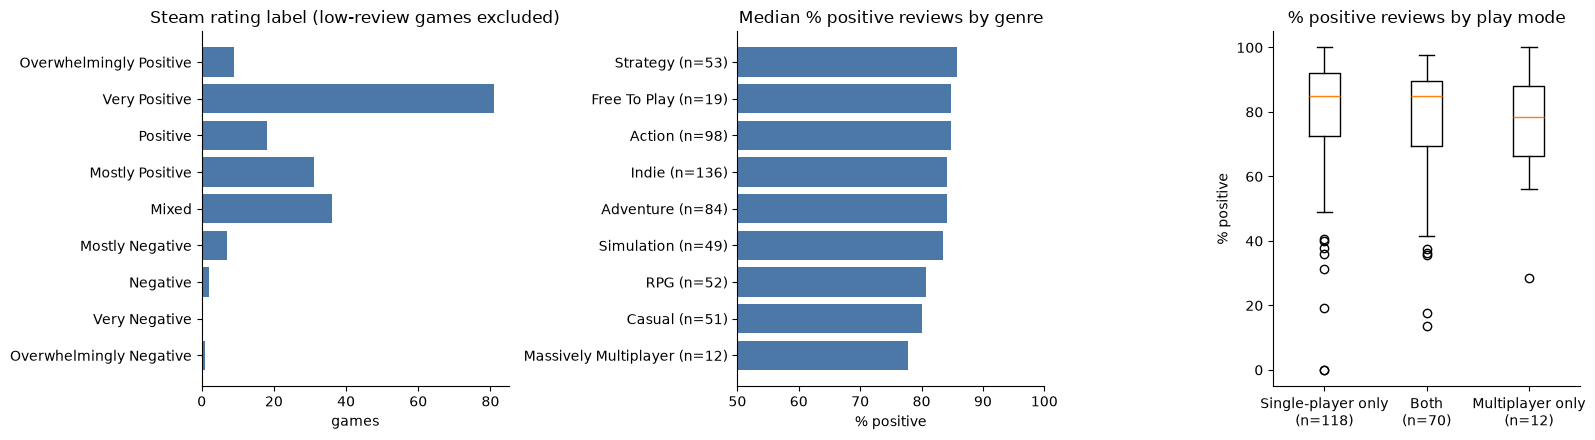

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Rating distribution
rc = final["rating_label"].value_counts().reindex(RATING_ORDER).fillna(0)
axes[0].barh(rc.index, rc.values, color="#4C78A8")
axes[0].set_title("Steam rating label (low-review games excluded)")
axes[0].set_xlabel("games")

# Review score by genre (genres with at least 10 games)
gcols = [c for c in final if c.startswith("genre_")]
g = pd.DataFrame({c[6:].replace("_", " ").title().replace("Rpg", "RPG"): [final.loc[final[c] == 1, "positive_percentage"].median(),
                                                   int(final[c].sum())] for c in gcols},
                 index=["median_pos", "n"]).T
g = g[g["n"] >= 10].sort_values("median_pos")
axes[1].barh([f"{i} (n={int(n)})" for i, n in zip(g.index, g["n"])], g["median_pos"], color="#4C78A8")
axes[1].set_title("Median % positive reviews by genre")
axes[1].set_xlabel("% positive")
axes[1].set_xlim(50, 100)

# Multiplayer vs single-player only
grp = final.assign(mode=np.select([final["multiplayer"] & final["single_player"], final["multiplayer"]],
                                  ["Both", "Multiplayer only"], "Single-player only"))
order_m = ["Single-player only", "Both", "Multiplayer only"]
data = [grp.loc[grp["mode"] == m, "positive_percentage"].dropna() for m in order_m]
axes[2].boxplot(data, tick_labels=[f"{m}\n(n={len(d)})" for m, d in zip(order_m, data)])
axes[2].set_title("% positive reviews by play mode")
axes[2].set_ylabel("% positive")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

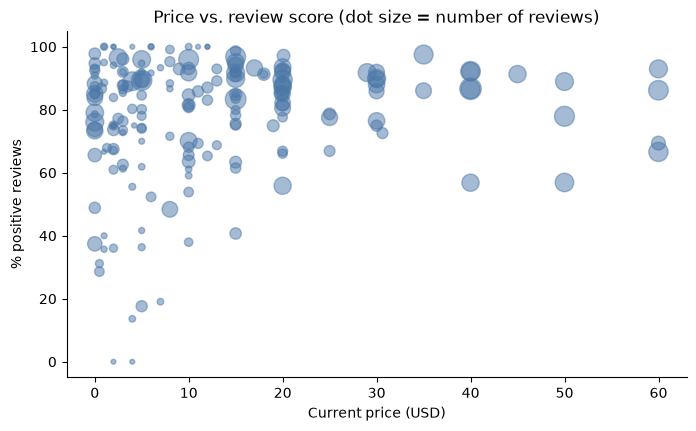

,median,count
perspective,,
Top-Down,87.2,8
First-Person,85.1,50
Third Person,82.9,24
Isometric,78.7,11


,median,count
art_style,,
Retro,89.7,8
Colorful,89.2,7
Anime,87.1,19
Pixel Graphics,86.5,20
Stylized,85.8,5
Realistic,84.6,23
Minimalist,83.9,7
Cute,83.7,8


,median,count
narrative,,
Choices Matter,89.6,5
Visual Novel,87.1,11
Multiple Endings,84.6,5
Story Rich,84.0,34
Interactive Fiction,75.0,5


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
paid = final[final["final_price"].notna()]
ax.scatter(paid["final_price"], paid["positive_percentage"], s=12 + 6 * paid["log_total_reviews"] ** 2,
           alpha=0.5, color="#4C78A8")
ax.set_xlabel("Current price (USD)")
ax.set_ylabel("% positive reviews")
ax.set_title("Price vs. review score (dot size = number of reviews)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

if HAVE_TAGS:
    for dim in ("perspective", "art_style", "narrative"):
        t = final.groupby(dim)["positive_percentage"].agg(["median", "count"]).query("count >= 5")
        display(t.sort_values("median", ascending=False).round(1).rename_axis(dim))